In [33]:
import pandas as pd
import numpy as np
import csv

from math import degrees
from math import degrees

df = pd.read_csv("sim2real_log.csv")

In [34]:
df.describe()

,t,cmd1,cmd2,cam1,cam2
count,1.296000e+03,1296.000000,1296.000000,1296.000000,1296.000000
mean,3.941945e+01,1.966179,1.190236,1.928329,1.248829
std,2.262576e+01,0.267626,0.268263,0.243314,0.260789
min,7.152557e-07,1.557514,0.813250,1.537592,0.825754
25%,2.013491e+01,1.710731,0.923873,1.688775,1.004816
50%,3.829861e+01,1.989579,1.187008,1.951243,1.250481
75%,5.907254e+01,2.229026,1.451776,2.164889,1.504432
max,7.999244e+01,2.328340,1.584079,2.270490,1.650817


In [35]:
df = df[df["t"] >= 1] 
df["err1"] = np.degrees(df["cam1"] - df["cmd1"])
df["err2"] = np.degrees(df["cam2"] - df["cmd2"])

# ROOT MEAN SQUARE

In [36]:
mean1 = df["err1"].mean()
mean2 = df["err2"].mean()

# df["err1"] = df["err1"].fillna(mean1)
# df["err2"] = df["err2"].fillna(mean2)

RMS_1 = ((df["err1"]**2).mean()) ** 0.5
RMS_2 = ((df["err2"]**2).mean()) ** 0.5

print(f"(degrees)\nmean1 = {mean1:.2f} | mean2 = {mean2:.2f} \nRMS 1: {RMS_1} \nRMS 2: {RMS_2}")

(degrees)
mean1 = -2.18 | mean2 = 3.38 
RMS 1: 5.446403110832838 
RMS 2: 6.702605583014275


### worst error

In [37]:
w_err1 = df["err1"].abs().idxmax()
w_err2 = df["err2"].abs().idxmax() 

print(f"""
worst error from servo 1: {df.loc[w_err1, "err1"]:.2f}
worst error from servo 2: {df.loc[w_err2, "err2"]:.2f}
""")


worst error from servo 1: -11.55
worst error from servo 2: -13.88



### The varying error

In [39]:
varying_left = (RMS_1**2 - mean1**2) ** 0.5
varying_right = (RMS_2**2 - mean2**2) ** 0.5

print(f"""
varying error from left servo: {varying_left:.2f}
varying error from right servo: {varying_right:.2f}
""")


varying error from left servo: 4.99
varying error from right servo: 5.79



# PLOT

<Axes: title={'center': 'right servo'}, xlabel='t'>

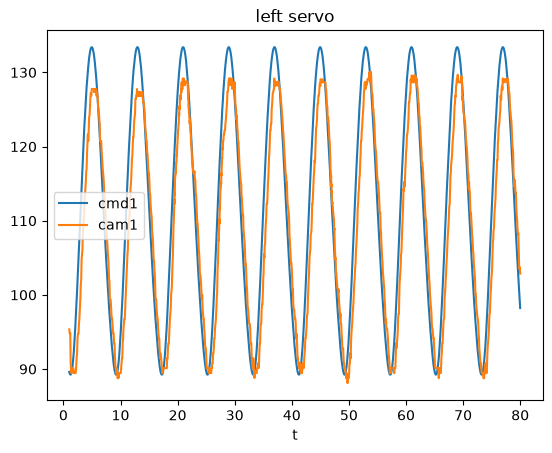

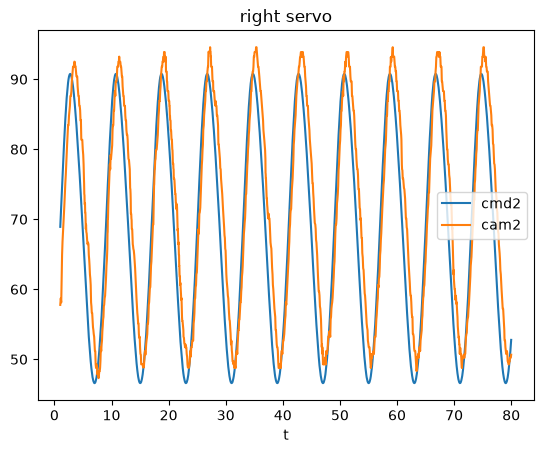

In [40]:
deg = np.degrees(df[["cmd1", "cam1", "cmd2", "cam2"]])
deg["t"] = df["t"]

deg.plot(x="t", y=["cmd1", "cam1"], title="left servo")
deg.plot(x="t", y=["cmd2", "cam2"], title="right servo")

In [41]:
n = 15
for lag in np.arange(0,1, 1/n):
    cmd_late = np.interp(df["t"] - lag, df["t"], df["cmd1"])   # the command, delayed by `lag` seconds
    err = (df["cam1"] - cmd_late) * 180 / np.pi
    print(f"{lag:.2f}, {round((err**2).mean() ** 0.5, 2)}")

0.00, 5.45
0.07, 4.82
0.13, 4.23
0.20, 3.7
0.27, 3.27
0.33, 2.97
0.40, 2.85
0.47, 2.93
0.53, 3.2
0.60, 3.61
0.67, 4.12
0.73, 4.69
0.80, 5.31
0.87, 5.96
0.93, 6.63


# CONCLUSION

### Sim2real gap
over 10 loops of a 50 mm circle (8 s per loop), the real crank angles differed from the commanded angles by 5.8° RMS (left) and 5.6° (right), worst case 11° and 17°.

- **Main cause, lag:** the real arm follows the commanded path about 0.4 s late (right: [] s). Delaying the command by that amount reduces the error to 3.0° (right: []°).
- **Second cause, offset:** most of what remains is a constant offset of −2.6° (left) and +0.7° (right), a calibration issue.
- **The rest:** (backlash, wobble, camera noise) is only about 1.5°.Caveat; part of the 0.4 s comes from the camera, which delivers each frame roughly 0.1 s late. So the servos alone are about 0.3 s behind.